# BrushCue Example: Lens Blur

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/lens_blur.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/lens-blur

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


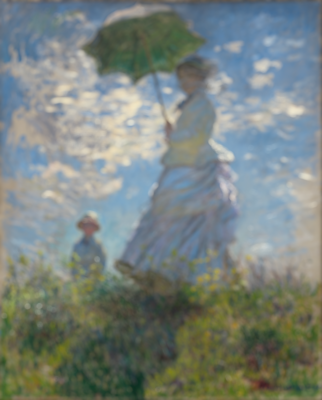

In [1]:
import io
from PIL import Image

import brushcue as bc

blur_radius = 16.0
highlights = 0.5
input_image = bc.Composition.monet_women_with_parasol()
input_bounds = input_image.bounds()
graph = input_image.spacial_effect_shader(
    "let lo = image_bounds.xy + vec2<f32>(0.5);\nlet hi = image_bounds.zw - vec2<f32>(0.5);\nlet count = clamp(i32(blur_radius * blur_radius * 0.75), 32, 640);\nvar total = vec4<f32>(0.0);\nvar weight_sum = 0.0;\nfor (var i = 0; i < count; i = i + 1) {\n    let t = (f32(i) + 0.5) / f32(count);\n    let r = sqrt(t) * blur_radius;\n    let theta = f32(i) * 2.3999632;\n    let p = clamp(position + vec2<f32>(cos(theta), sin(theta)) * r, lo, hi);\n    let c = sample(p);\n    let luma = dot(c.rgb, vec3<f32>(0.2126, 0.7152, 0.0722));\n    let w = 1.0 + highlights * 24.0 * pow(clamp(luma, 0.0, 1.0), 6.0);\n    total = total + vec4<f32>(c.rgb * c.a, c.a) * w;\n    weight_sum = weight_sum + w;\n}\nlet avg = total / weight_sum;\nreturn vec4<f32>(avg.rgb / max(avg.a, 0.0001), avg.a);",
    "",
    blur_radius,
    bc.Dictionary.create()
    .add("blur_radius", blur_radius)
    .add("highlights", highlights)
    .add("image_bounds", input_bounds),
    bc.ColorRepresentation.aces_cg(),
).crop(input_bounds)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
